# Tarea 1 – Analítica de Datos (MACI 2026)

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

Las cifras de las interpretaciones corresponden a la extracción del **27-10-2026**. Si vuelves a correr el scraping, los precios cambian: revisa los números antes de entregar.

## Preguntas de exploración

### Pregunta A: TOP 3 - Marcas con el precio más alto
Para las 3 marcas con el precio promedio más alto (considerando el precio de un mismo modelo en distintas tiendas), presenta sus estadísticas descriptivas (media, desviación estándar, mínimo, máximo, cuartiles) y haz una pequeña interpretación. Utiliza solo los precios en ofertas de los celulares no reacondicionados.

In [1]:
# Librerías que usa este notebook
import pandas as pd                    # tablas
import matplotlib.pyplot as plt        # gráfico de la pregunta c
from pathlib import Path               # rutas de carpetas

# Ruta a data/processed: la busca subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz)
PROC = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "processed").is_dir())

clean = pd.read_csv(PROC / "data_processed.csv")      # datos limpios del notebook 02
print(clean.shape, "← cargado desde", PROC / "data_processed.csv")

(980, 14) ← cargado desde /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed/data_processed.csv


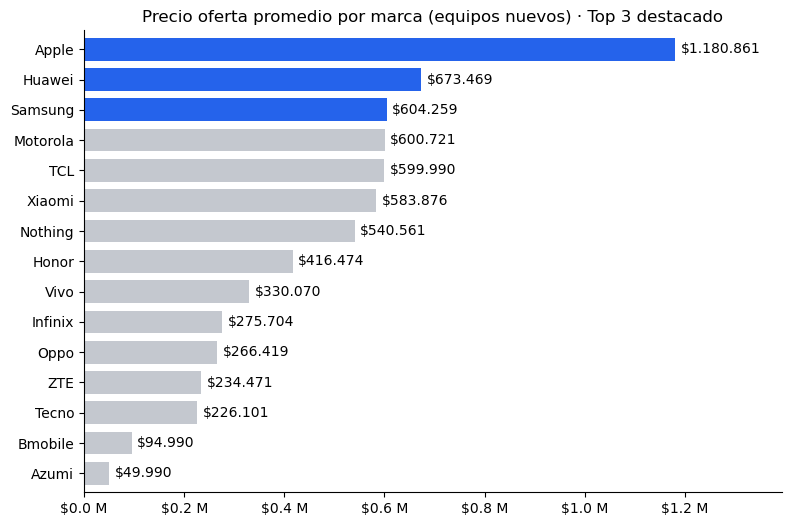

In [2]:
nuevos = clean[clean.reacondicionado == 0]                                 # solo equipos nuevos
top3 = nuevos.groupby("marca").precio_oferta.mean().nlargest(3).index      # 3 marcas con mayor precio promedio

prom = nuevos.groupby("marca").precio_oferta.mean().sort_values()          # promedio por marca, de menor a mayor
colores = ["#2563eb" if m in top3 else "#c4c8cf" for m in prom.index]      # top 3 en azul, el resto en gris

ax = prom.plot.barh(color=colores, figsize=(9, 6), width=0.75)             # barras horizontales: nombres legibles
etiquetas = [f"${v:,.0f}".replace(",", ".") for v in prom]                 # monto en todas las barras: 645953 → $645.953
ax.bar_label(ax.containers[0], labels=etiquetas, padding=4)                # escribe cada monto al final de su barra
ax.set_xlim(right=prom.max() * 1.18)                                       # 18 % de espacio extra para que el monto mayor no se corte
ax.set(title="Precio oferta promedio por marca (equipos nuevos) · Top 3 destacado", xlabel="", ylabel="")
ax.xaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f} M")               # eje en millones: 1.200.000 → $1.2 M
ax.spines[["top", "right"]].set_visible(False)                             # quita bordes que no aportan
plt.show()

**Interpretación del ranking.**
- **Apple lidera sola:** su promedio de **\$1.180.861** es 1,75 veces el de Huawei (\$673.469), la segunda.

- **Huawei es segunda**, un 10,3 % sobre la tercera.

- **El tercer lugar es un empate técnico:** Samsung (\$604.259) supera a Motorola (\$600.721) por solo \$3.538 (0,6 %), a TCL (\$599.990) por 0,7 % y a Xiaomi (\$583.876) por 3,4 %. Bastó eliminar 26 ofertas duplicadas en la limpieza para que Samsung pasara a Motorola. El tercer lugar depende de diferencias mínimas y conviene leerlo con cautela.

- **TCL tiene un solo modelo nuevo y un solo precio:** su promedio es un dato puntual, no un patrón de la marca.

- **Escalones de precio:** bajo Nothing (\$540.561) hay un salto a Honor (\$416.474). Luego Vivo, Infinix, Oppo, ZTE y Tecno se agrupan entre \$226 y \$330 mil, y Bmobile y Azumi quedan bajo los \$100 mil.

In [3]:
nuevos = clean[clean.reacondicionado == 0]                                 # solo equipos nuevos
top3 = nuevos.groupby("marca").precio_oferta.mean().nlargest(3).index      # 3 marcas con mayor precio promedio
t3 = nuevos[nuevos.marca.isin(top3)]                                       # filas de esas 3 marcas
t3.groupby("marca").precio_oferta.describe().loc[top3].round(0)            # media, desv., mín., cuartiles y máx.

,count,mean,std,min,25%,50%,75%,max
marca,,,,,,,,
Apple,74.0,1180861.0,429129.0,479990.0,807490.0,1074990.0,1528740.0,2499990.0
Huawei,27.0,673469.0,436024.0,189990.0,394990.0,479990.0,866958.0,1699990.0
Samsung,184.0,604259.0,403546.0,119990.0,248454.0,493990.0,884990.0,2089990.0


**Interpretación de la tabla.**
- **Nivel de precio:** la media de Apple es 1,75 veces la de Huawei y 1,95 veces la de Samsung. Entre Huawei (\$673.469) y Samsung (\$604.259) hay \$69.210 de diferencia (10,3%).

- **Los cuartiles separan a Apple:** su Q1 (\$807.490) es casi igual al Q3 de Huawei (\$866.958) y de Samsung (\$884.990). El 25% más barato de los iPhone cuesta lo que el 25% más caro de las otras dos marcas.

- **Dispersión:** las tres tienen una desviación estándar parecida en pesos (\$404–436 mil). En relación con su media, Apple es la más homogénea (CV 36%); Huawei (65%) y Samsung (67%) venden en todo el espectro de precios.

- **Asimetría:** en las tres marcas la media supera a la mediana: pocos equipos muy caros inflan el promedio. El efecto es fuerte en Huawei (+40%), moderado en Samsung (+22%) y bajo en Apple (+10%). Para el precio típico, la mediana es más representativa.

- **Rango y tamaño de muestra:** Samsung va de \$119.990 a \$2.089.990 (17 veces) y es la cifra más robusta del grupo, con 184 precios de 26 modelos. Huawei tiene solo 27 precios de 12 modelos: es la menos robusta.

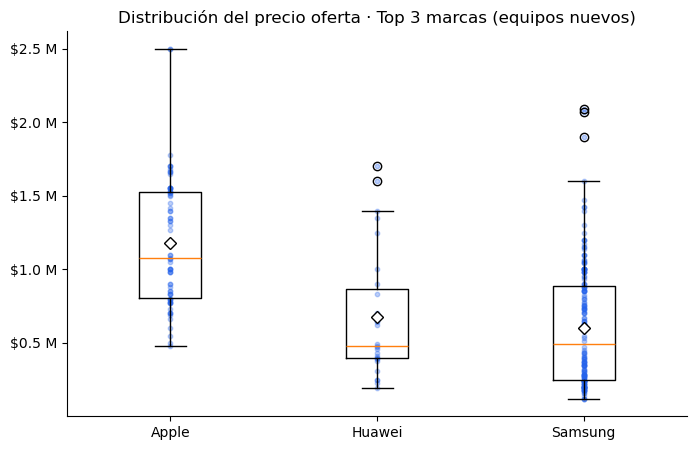

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([t3[t3.marca == m].precio_oferta for m in top3], tick_labels=top3, showmeans=True,   # una caja por marca
           meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))         # ◇ = media
for i, m in enumerate(top3, 1):                                            # puntos: cada precio real, semitransparente
    ax.scatter([i] * (t3.marca == m).sum(), t3[t3.marca == m].precio_oferta, s=10, alpha=0.3, color="#2563eb")
ax.yaxis.set_major_formatter(lambda y, _: f"${y/1e6:.1f} M")               # eje en millones
ax.set(title="Distribución del precio oferta · Top 3 marcas (equipos nuevos)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Interpretación del boxplot.**
- **Apple está en otro nivel:** su caja (\$807 mil – \$1,53 M) queda completa sobre las medianas de Huawei y Samsung, y no tiene valores atípicos. Incluso el iPhone Duo (\$2.499.990) cae dentro de su rango esperado (límite \$2,61 M).

- **Huawei y Samsung comparten el precio típico:** sus medianas están a solo \$14.000 (\$479.990 contra \$493.990). La caja de Samsung baja más (Q1 \$248.454 contra \$394.990) porque tiene más presencia en la gama de entrada: el 27% de sus precios está bajo \$250.000, contra el 15% de Huawei.

- **Valores atípicos:**
  - Huawei tiene 2, ambos en Huawei Shop y sobre su límite de \$1,57 M: el Mate X7 plegable (\$1.599.990) y el Mate 80 Pro (\$1.699.990).

  - Samsung tiene 3, sobre su límite de \$1,84 M: el Galaxy Z Fold7 en Ripley (\$1.899.990) y en Travel Tienda (\$2.069.990), y el Galaxy S25 Ultra en PC Factory (\$2.089.990). Ese mismo S25 Ultra se vende desde \$799.990 en otra tienda: el atípico refleja la **dispersión entre tiendas**, no un producto distinto.

- En las tres marcas el rombo (media) queda sobre la línea naranja (mediana), lo que confirma la asimetría de la tabla.

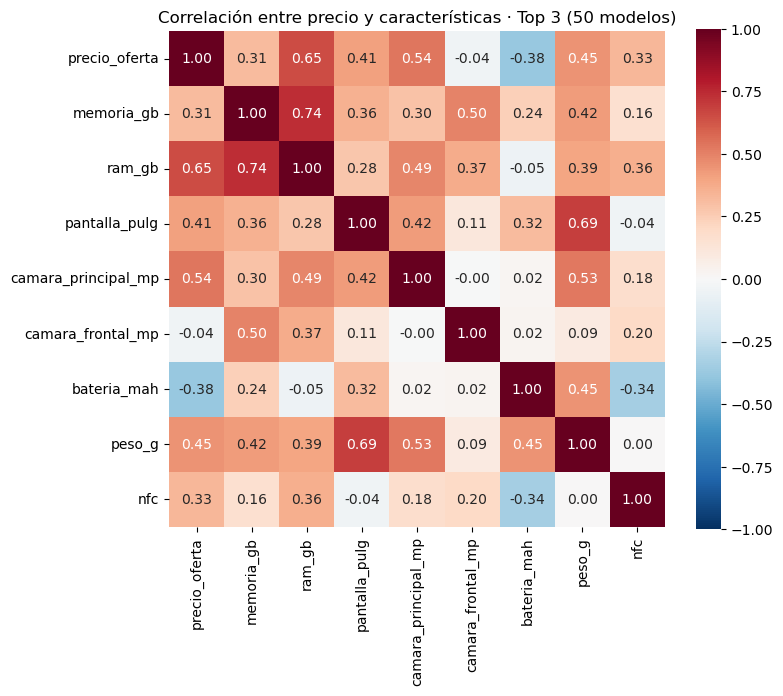

In [5]:
import seaborn as sns
cols = ["precio_oferta", "memoria_gb", "ram_gb", "pantalla_pulg", "camara_principal_mp",
        "camara_frontal_mp", "bateria_mah", "peso_g", "nfc"]
modelos = t3.groupby("nombre")[cols].median()          # 1 fila por modelo: precio = mediana entre tiendas
plt.figure(figsize=(8, 6.5))
sns.heatmap(modelos.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)   # rojo +, azul −
plt.title(f"Correlación entre precio y características · Top 3 ({len(modelos)} modelos)")
plt.show()

**Interpretación del mapa de correlación (50 modelos, uno por fila).**
- **Lo que más se asocia al precio:** la RAM (0,65), la cámara principal (0,54), el peso (0,45) y la pantalla (0,41). Los equipos con más RAM, mejores cámaras y más grandes (Ultra, Pro Max y plegables) son los más caros. El NFC (0,33) y la memoria (0,31) tienen una relación moderada.

- **La batería (−0,38) no significa que más mAh abarate el equipo.** Se suman dos efectos:
  - Mezclar marcas: Apple, la más cara, usa baterías más chicas (mediana 3.521 mAh contra 5.000 de Samsung y 5.335 de Huawei).
  - Dentro de Samsung y Huawei, la gama de entrada compite con baterías grandes (ver a.5).

- **NFC (0,33):** 6 de los 7 modelos sin NFC son de entrada (5 Galaxy A de \$175–250 mil y el Huawei Nova Y74). La excepción es el Huawei Mate 80 Pro.

- **La cámara frontal (−0,04) no se relaciona con el precio.**

- **Las características se mueven juntas:** memoria–RAM (0,74), pantalla–peso (0,69) y cámara–peso (0,53). Un equipo de gama alta trae todo "más grande" a la vez. Esto importa para el Objetivo 2: varias variables cuentan la misma historia, así que el modelo se reparte la importancia entre ellas.

- **Cautela:** la correlación de Pearson solo mide relaciones lineales, no prueba causalidad y aquí se calcula sobre 50 modelos.

In [6]:
pd.DataFrame({m: t3[t3.marca == m].groupby("nombre")[cols].median().corr().precio_oferta for m in top3}
            ).drop("precio_oferta").round(2)               # cada columna: una marca; cada fila: una característica

,Apple,Huawei,Samsung
memoria_gb,0.64,0.60,0.68
ram_gb,0.78,0.70,0.83
pantalla_pulg,0.92,0.65,0.50
camara_principal_mp,0.66,0.94,0.62
camara_frontal_mp,0.31,-0.34,0.43
bateria_mah,0.36,-0.38,-0.46
peso_g,0.90,0.73,0.25
nfc,NaN,-0.07,0.51


**Interpretación: cada marca cobra por algo distinto.**
- **Apple cobra por tamaño:** pantalla (0,92) y peso (0,90). El precio sube de iPhone base a Pro Max y Duo. En Apple la batería correlaciona positivamente (+0,36), porque los equipos grandes traen baterías grandes. Su NFC aparece vacío (NaN) porque todos los iPhone lo tienen: una variable que no cambia no puede correlacionar.

- **Huawei cobra por cámara:** la cámara principal llega a 0,94. Va de 50 MP en el Nova Y73 (\$189.990) a 152,5 MP sumados en el Pura 80 Ultra (\$1.374.990). Sus líneas premium, Pura y Mate, se venden por fotografía.

- **Samsung cobra por RAM:** 0,83. Escala de 4 GB en los Galaxy A07/A17 (bajo \$215 mil) a 12 GB en las líneas S y Fold (desde \$713 mil). El NFC (0,51) también separa: solo los Galaxy A de entrada no lo traen.

- **En Samsung y Huawei, la batería es la carta de la gama de entrada:** correlaciona −0,46 y −0,38 con el precio. Los equipos baratos traen las baterías más grandes, como el Galaxy A07 5G (6.000 mAh, \$204.990) o el Nova 15 Max (8.497 mAh, \$394.990). Los compactos de gama alta sacrifican batería: el Galaxy S25 tiene 4.000 mAh.

- **Cautela:** con 12 a 26 modelos por marca, un solo equipo puede mover el coeficiente.

#### Conclusión de la pregunta A
- **Apple es la única marca 100 % premium:** el 97 % de sus precios supera los \$500.000 y su precio típico (mediana \$1.074.990) es más del doble que el de las otras dos.

- **Huawei y Samsung son marcas de espectro completo:** sus medianas (\$479.990 y \$493.990) están bajo el medio millón, y sus promedios se inflan por plegables y gama Ultra.

- **El tercer lugar es un empate técnico** entre Samsung, Motorola y TCL (menos del 1 % de diferencia).

**Lectura para la emprendedora:** fuera de Apple, el precio típico de las marcas caras ronda los \$480–495 mil. Competir contra sus promedios es competir contra sus flagships. Cada marca cobra por algo distinto (Apple por tamaño, Huawei por cámara, Samsung por RAM), y en la gama de entrada el argumento común es la batería grande. Una marca nueva bajo los \$400 mil debería competir con batería y almacenamiento a buen precio; para subir de tramo, el mercado premia RAM y cámara principal.

### Pregunta B: Ripley vs. Falabella vs. Paris
Filtra tu base de datos para incluir únicamente los celulares vendidos por las tiendas Ripley, Falabella y Paris. Compara el precio promedio de los celulares en cada una de estas tres tiendas y determina cuál es, en promedio, la más cara y cuál la más barata. Utiliza solo los precios en ofertas de los celulares no reacondicionados. Haz una pequeña interpretación.

Se usan los nombres exactos "Ripley", "Falabella" y "Paris". "Ripley Marketplace" y "Falabella Marketplace" quedan fuera por ser vendedores terceros.

               mean    median  count
tienda                              
Paris      502500.0  399990.0     51
Falabella  570481.0  429990.0     55
Ripley     571220.0  389990.0     61

25 modelos en común | veces que cada tienda tiene el menor precio: {'Falabella': 10, 'Paris': 15, 'Ripley': 7}


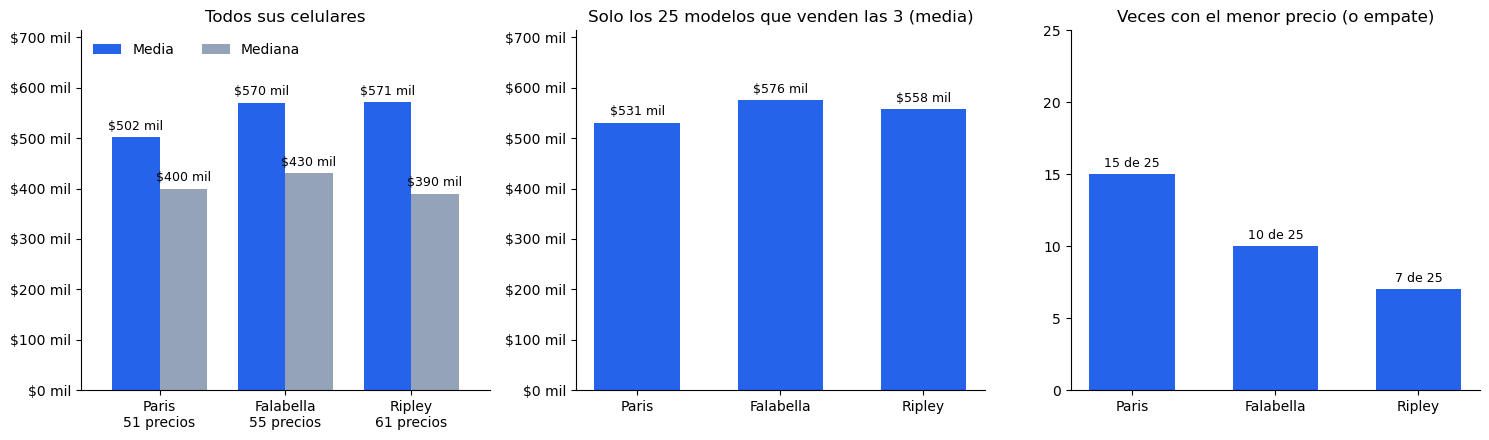

tienda
Paris        530910.0
Ripley       557990.0
Falabella    576390.0
dtype: float64

In [8]:
tres = nuevos[nuevos.tienda.isin(["Ripley", "Falabella", "Paris"])]      # solo esas 3 tiendas, equipos nuevos
res = tres.groupby("tienda").precio_oferta.agg(["mean", "median", "count"]).sort_values("mean")   # resumen por tienda
print(res.round(0))

# Control: cada tienda vende celulares distintos, y eso mueve su promedio. Comparamos solo los modelos que venden las 3.
comun = tres.pivot_table(index="nombre", columns="tienda", values="precio_oferta").dropna()   # 1 fila por modelo, 1 columna por tienda
veces = (comun.rank(axis=1, method="min") == 1).sum()                     # rank 1 = la más barata para ese modelo (o empatada)
print(f"\n{len(comun)} modelos en común | veces que cada tienda tiene el menor precio:", veces.to_dict())

# Gráficos: 3 paneles con las tiendas en el mismo orden (de menor a mayor promedio simple)
orden = res.index
miles = lambda v: f"${v/1e3:,.0f} mil".replace(",", ".")                  # 570481 → $570 mil
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: media y mediana con TODOS los celulares de cada tienda
res[["mean", "median"]].set_axis(["Media", "Mediana"], axis=1).plot.bar(ax=a1, color=["#2563eb", "#94a3b8"], rot=0, width=0.75)
a1.set_xticks(range(len(orden)), [f"{t}\n{n:.0f} precios" for t, n in res["count"].items()])   # nombre + n° de precios
for cont in a1.containers: a1.bar_label(cont, labels=[miles(v) for v in cont.datavalues], padding=3, fontsize=9)
a1.set_ylim(top=res["mean"].max() * 1.25)                                  # espacio para la leyenda
a1.legend(loc="upper left", ncol=2, frameon=False)
a1.set(title="Todos sus celulares", xlabel="")

# Panel 2: media con SOLO los modelos que venden las 3 (misma escala que el panel 1, para comparar)
a2.bar(orden, comun.mean()[orden], color="#2563eb", width=0.6)
a2.bar_label(a2.containers[0], labels=[miles(v) for v in comun.mean()[orden]], padding=3, fontsize=9)
a2.set_ylim(a1.get_ylim())
a2.set(title=f"Solo los {len(comun)} modelos que venden las 3 (media)")

# Panel 3: en cuántos de esos modelos cada tienda es la más barata
a3.bar(orden, veces[orden], color="#2563eb", width=0.6)
a3.bar_label(a3.containers[0], labels=[f"{v} de {len(comun)}" for v in veces[orden]], padding=3, fontsize=9)
a3.set_ylim(top=len(comun))                                                # eje hasta el total de modelos en común
a3.set(title="Veces con el menor precio (o empate)")

for a in (a1, a2): a.yaxis.set_major_formatter(lambda y, _: miles(y))     # eje en miles de pesos
for a in (a1, a2, a3): a.spines[["top", "right"]].set_visible(False)       # quita bordes que no aportan
plt.tight_layout()
plt.show()

comun.mean().sort_values().round(0)

**Interpretación:**

- Todos sus celulares: media y mediana de cada tienda, con su número de precios bajo el nombre. Se ve el efecto de la mezcla: Ripley tiene la mediana más baja ($390 mil) pero la media más alta ($571 mil), porque combina muchos equipos baratos con algunos muy caros.

- Solo los 25 modelos en común: compara el mismo celular en las tres tiendas. Ripley y Falabella intercambian lugar: ahora Falabella es la más cara ($576 mil). Tiene la misma escala que el panel 1, así que las alturas se comparan directo.

- Veces con el menor precio: Paris es la más barata, o empata, en 15 de los 25 modelos; Falabella en 10 y Ripley en 7.

Los tres paneles suman 32 y no 25 porque, cuando dos tiendas empatan en el precio más bajo, el modelo cuenta para ambas. Por eso el título dice “(o empate)”.

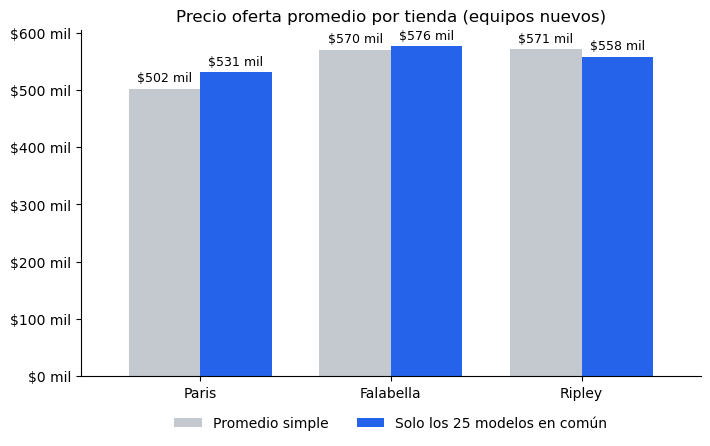

In [9]:
comp = pd.DataFrame({"Promedio simple": tres.groupby("tienda").precio_oferta.mean(),
                     f"Solo los {len(comun)} modelos en común": comun.mean()}).sort_values("Promedio simple")
ax = comp.plot.bar(color=["#c4c8cf", "#2563eb"], figsize=(8, 4.5), width=0.75, rot=0)
for cont in ax.containers:                                                 # monto sobre cada barra
    ax.bar_label(cont, labels=[f"${v/1e3:,.0f} mil".replace(",", ".") for v in cont.datavalues], padding=3, fontsize=9)
ax.set(title="Precio oferta promedio por tienda (equipos nuevos)", xlabel="", ylabel="")
ax.yaxis.set_major_formatter(lambda y, _: f"${y/1e3:,.0f} mil".replace(",", "."))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)   # leyenda bajo el gráfico, sin tapar barras
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### Conclusión de la pregunta B
**Interpretación.**
- **Promedio simple:** **Paris es la más barata (\$502.500)**. Ripley (\$571.220) y Falabella (\$570.481) quedan prácticamente empatadas como las más caras: Ripley supera a Falabella por solo \$739.

- **El promedio simple compara catálogos distintos** (51, 55 y 61 modelos). Por ejemplo, Ripley tiene la mediana más baja (\$389.990) pero una de las medias más altas: mezcla muchos equipos baratos con algunos muy caros.

- **Control con los mismos celulares:** en los **25 modelos que venden las tres tiendas**, Paris sigue siendo la más barata (\$530.910), seguida de Ripley (\$557.990), y **Falabella es la más cara (\$576.390)**. La brecha es del 8,6 % (≈ \$45 mil). Paris tiene el menor precio, o empata, en 15 de los 25 modelos.

- **Conclusión:**
  - **Paris es la más barata** con ambos métodos, así que el resultado es robusto.
  - **La más cara depende de cómo se mida:** Ripley por promedio simple, en un empate técnico con Falabella; pero comparando el mismo celular, Falabella cobra más.
  - Para la emprendedora, Paris es el canal con precios más agresivos y la referencia para fijar un precio competitivo en retail.

### Pregunta C: Modelos únicos por marca
Muestra cuántos modelos de celular únicos ofrece cada marca en el mercado (sin contar el mismo modelo vendido en diferentes tiendas). Presenta esta información en un gráfico de barras ordenado de mayor a menor. Haz una pequeña interpretación.

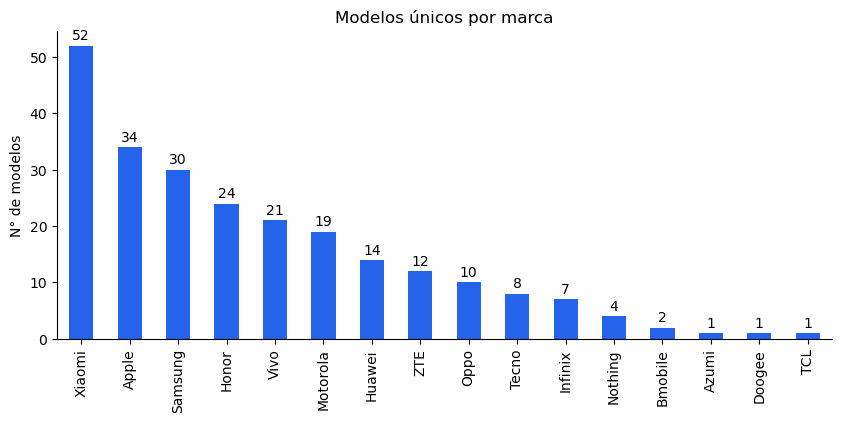

In [10]:
por_marca = clean.groupby("marca").nombre.nunique().sort_values(ascending=False)   # modelos distintos por marca (nuevos y reacondicionados)
ax = por_marca.plot.bar(figsize=(10, 4), color="#2563eb", title="Modelos únicos por marca", ylabel="N° de modelos", xlabel="")
ax.bar_label(ax.containers[0], padding=2)                                  # cantidad sobre cada barra
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### Conclusión de la pregunta C
**Interpretación.**
- El mercado tiene **240 modelos de 16 marcas**. **Xiaomi lidera con 52**, seguida de Apple (34) y Samsung (30). Esas 3 marcas suman el **48%** del catálogo, y con Honor (24) y Vivo (21) las 5 primeras llegan al **67%**.

- **Cola larga:** Bmobile tiene 2 modelos, y Doogee, Azumi y TCL tienen uno cada una.

- **Matiz de Apple:** sus 34 modelos incluyen reacondicionados. Solo 12 se venden nuevos; los otros 22 son iPhone de generaciones anteriores que solo se ofrecen reacondicionados o usados. Esto revela un mercado de segunda mano relevante. Xiaomi, en cambio, ofrece 47 de sus 52 modelos nuevos.

- Cada "modelo" es una variante (nombre del producto), tal como pide el enunciado.

- **Lectura para la emprendedora:** el mercado está concentrado en pocas marcas con portafolios amplios. Xiaomi compite con muchas variantes en todos los rangos de precio. Una marca nueva no puede ganar por amplitud de catálogo: le conviene un portafolio corto, enfocado en el rango de precio donde su relación características/precio sea mejor.

## Otros análisis exploratorios

In [20]:
m = clean.drop_duplicates("nombre")                                       # 1 fila por modelo: cada celular cuenta una vez
ofertas = clean.nombre.value_counts()                                     # n° de ofertas (tienda + condición) de cada modelo
print(f"{len(m)} modelos únicos | {len(clean)} ofertas | ofertas por modelo: mediana {ofertas.median():.0f}, máximo {ofertas.max()}")

# Marcas: las 6 con más modelos tienen color propio; el resto se agrupa en "Otras" (más de 7 colores no se distinguen)
top6 = list(m.marca.value_counts().index[:6])
marca7 = m.marca.where(m.marca.isin(top6), "Otras").rename("Marca")
colores = dict(zip(top6 + ["Otras"], ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7", "#c4c8cf"]))   # apta para daltonismo

# Agrupa una columna numérica en tramos [desde, hasta)
tramo = lambda col, cortes, etiquetas: pd.cut(m[col], cortes, labels=etiquetas, right=False)

def barras(s, titulo, rot=0):                                             # barras simples con n° y % de los modelos
    ax = s.plot.bar(figsize=(9, 4.5), color="#2563eb", width=0.75, rot=rot)
    ax.bar_label(ax.containers[0], labels=[f"{v}\n{v/len(m):.0%}" for v in s], padding=2, fontsize=9)
    ax.set_ylim(top=s.max() * 1.25)                                       # espacio para las etiquetas
    ax.set(title=titulo, xlabel="", ylabel="N° de modelos")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

def barras_marca(grupo, titulo):                                          # barras apiladas: cada segmento es una marca
    t = pd.crosstab(grupo, marca7)[top6 + ["Otras"]]                      # filas: tramos; columnas: marcas (n° de modelos)
    ax = t.plot.bar(stacked=True, figsize=(10, 5), color=colores, width=0.75, rot=0, edgecolor="white", linewidth=1)
    ax.bar_label(ax.containers[-1], labels=[f"{v}\n{v/len(m):.0%}" for v in t.sum(axis=1)], padding=2, fontsize=9)   # total arriba
    ax.set_ylim(top=t.sum(axis=1).max() * 1.25)
    ax.set(title=titulo, xlabel="", ylabel="N° de modelos")
    ax.legend(title="Marca", loc="upper left", bbox_to_anchor=(1, 1), frameon=False)   # leyenda fuera del gráfico, a la derecha
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    return t                                                              # la tabla se muestra debajo del gráfico

240 modelos únicos | 980 ofertas | ofertas por modelo: mediana 2, máximo 20


### Ofertas por modelo (Top 15)

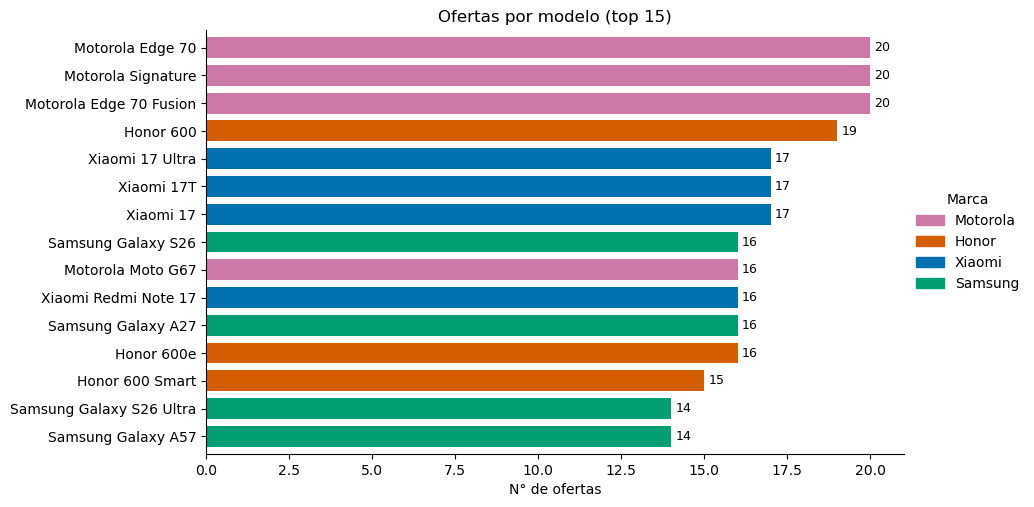

In [21]:
m7 = pd.Series(marca7.values, index=m.nombre)                            # marca (o "Otras") de cada modelo
top = ofertas.head(15)                                                    # 15 modelos con más ofertas
ax = top.rename(lambda n: n.split(" (")[0])[::-1].plot.barh(              # nombre sin la variante; el mayor arriba
    figsize=(9, 5.5), width=0.75, color=[colores[m7[n]] for n in top.index[::-1]])   # cada barra con el color de su marca
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
marcas = list(m7[top.index].unique())                                     # marcas presentes en el top 15
ax.legend([plt.Rectangle((0, 0), 1, 1, color=colores[b]) for b in marcas], marcas,
          title="Marca", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set(title="Ofertas por modelo (top 15)", xlabel="N° de ofertas", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Modelos con más ofertas por marca (Top 3)

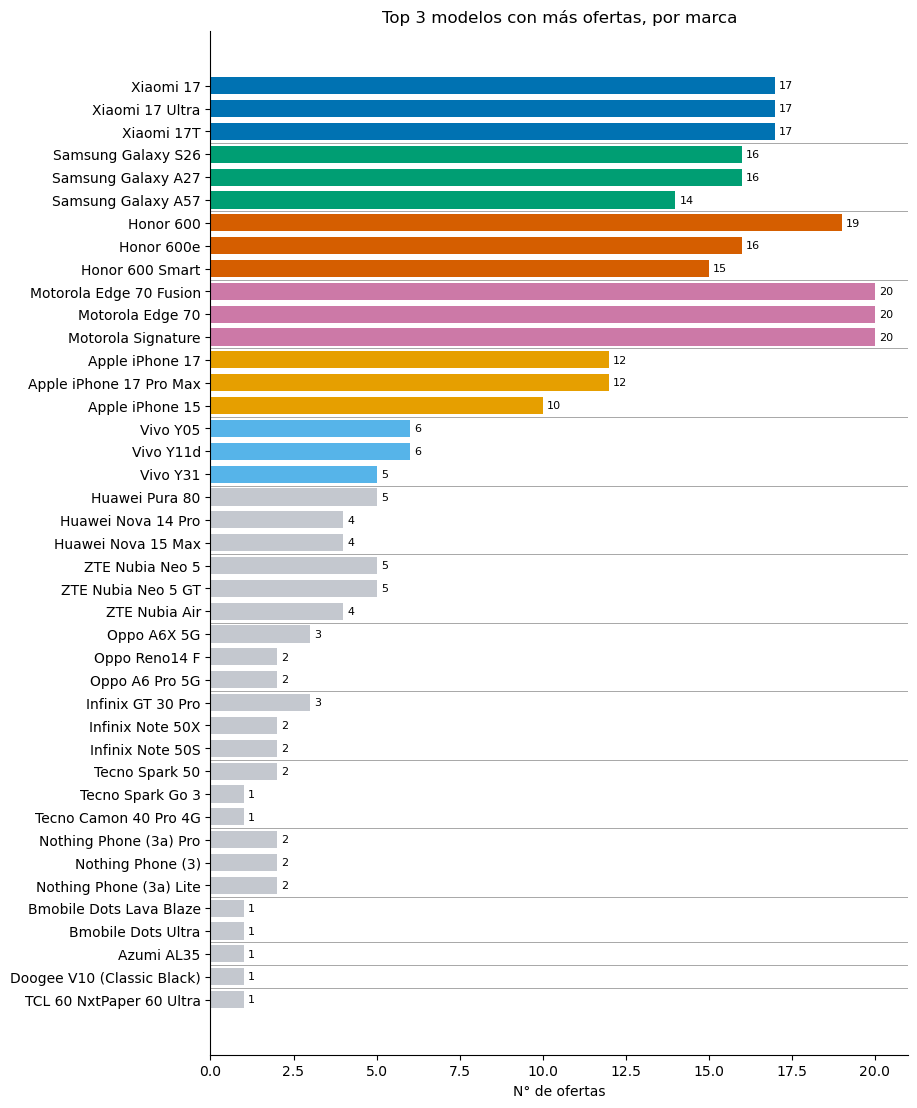

In [28]:
d = (clean.groupby(["marca", "nombre"]).size().rename("ofertas").reset_index()     # ofertas por modelo
       .sort_values("ofertas", ascending=False).groupby("marca").head(3))           # top 3 modelos de cada marca
d["total_marca"] = d.marca.map(clean.marca.value_counts())                          # ofertas totales de la marca (para ordenar)
d = d.sort_values(["total_marca", "ofertas"], ascending=False)                       # marcas de mayor a menor; dentro, modelos de mayor a menor
d["modelo"] = d.nombre.str.replace(r" \([^()]*GB.*$", "", regex=True)               # quita la variante "(256 GB / …)"

fig, ax = plt.subplots(figsize=(9, 0.3 * len(d) + 1))                              # alto según el n° de barras
ax.barh(range(len(d)), d.ofertas, color=d.marca.map(colores).fillna("#c4c8cf"), height=0.75)   # color de la marca (gris = "Otras")
ax.set_yticks(range(len(d)), d.modelo)
ax.invert_yaxis()                                                                    # la primera marca arriba
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
for y in (d.marca != d.marca.shift()).to_numpy().nonzero()[0][1:]:                  # línea divisoria donde cambia la marca
    ax.axhline(y - 0.5, color="#999", linewidth=0.6)
ax.set(title="Top 3 modelos con más ofertas, por marca", xlabel="N° de ofertas", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Modelos por pantalla según marca

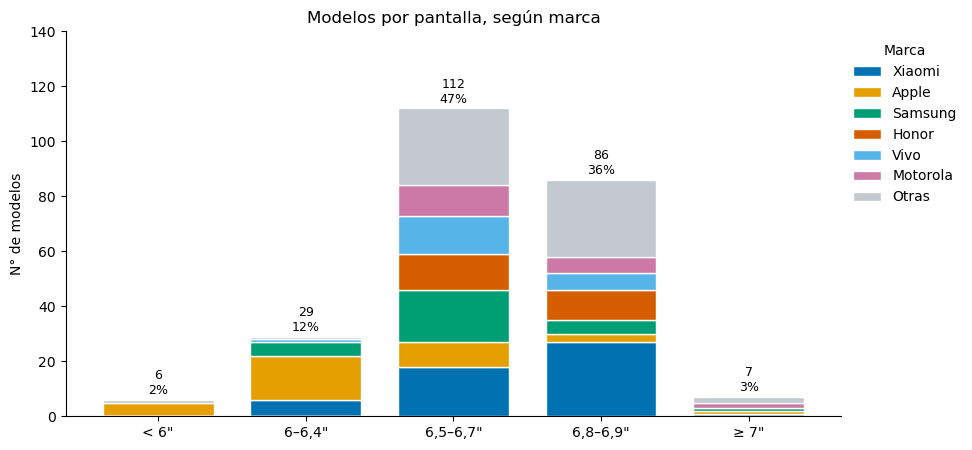

Marca,Xiaomi,Apple,Samsung,Honor,Vivo,Motorola,Otras
pantalla_pulg,,,,,,,
"< 6""",0,5,0,0,0,0,1
"6–6,4""",6,16,5,0,1,0,1
"6,5–6,7""",18,9,19,13,14,11,28
"6,8–6,9""",27,3,5,11,6,6,28
"≥ 7""",1,1,1,0,0,2,2


In [23]:
barras_marca(tramo("pantalla_pulg", [0, 6, 6.5, 6.8, 7, 99], ['< 6"', '6–6,4"', '6,5–6,7"', '6,8–6,9"', '≥ 7"']), "Modelos por pantalla, según marca")

### Modelos por peso según marca

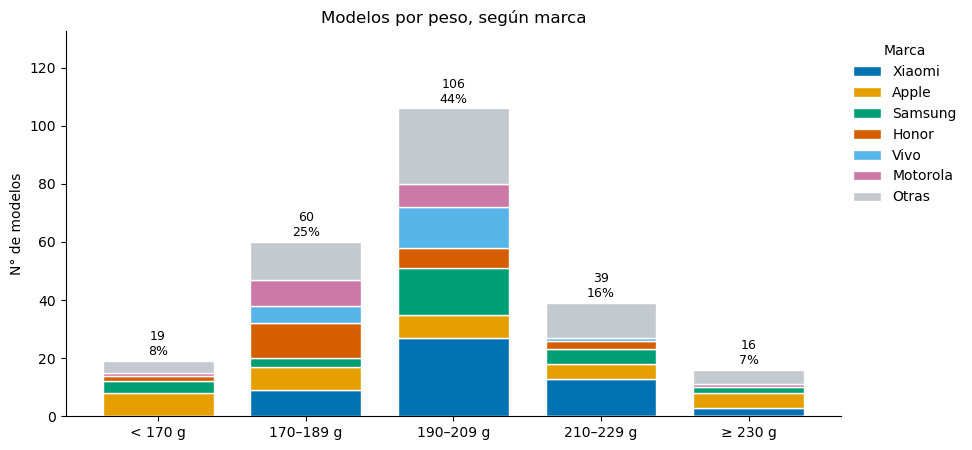

Marca,Xiaomi,Apple,Samsung,Honor,Vivo,Motorola,Otras
peso_g,,,,,,,
< 170 g,0,8,4,2,0,1,4
170–189 g,9,8,3,12,6,9,13
190–209 g,27,8,16,7,14,8,26
210–229 g,13,5,5,3,1,0,12
≥ 230 g,3,5,2,0,0,1,5


In [25]:
barras_marca(tramo("peso_g", [0, 170, 190, 210, 230, 999], ["< 170 g", "170–189 g", "190–209 g", "210–229 g", "≥ 230 g"]), "Modelos por peso, según marca")

### Modelos por RAM según marca

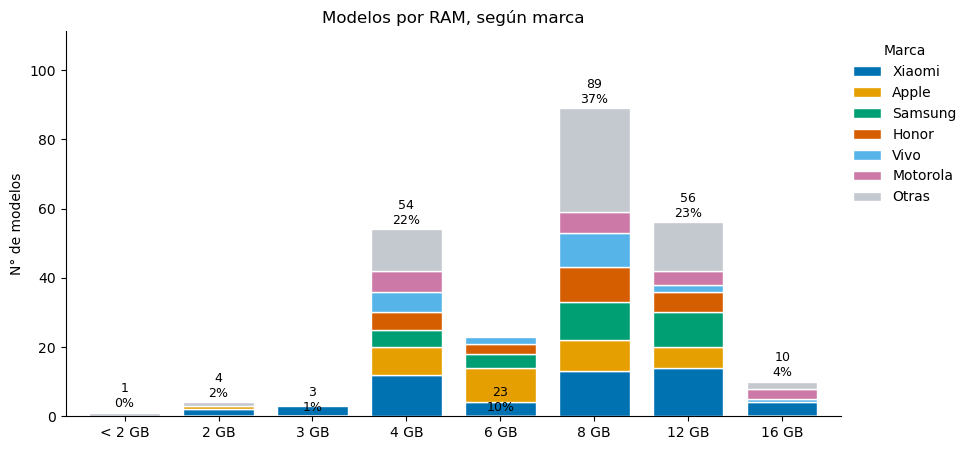

Marca,Xiaomi,Apple,Samsung,Honor,Vivo,Motorola,Otras
ram_gb,,,,,,,
< 2 GB,0,0,0,0,0,0,1
2 GB,2,1,0,0,0,0,1
3 GB,3,0,0,0,0,0,0
4 GB,12,8,5,5,6,6,12
6 GB,4,10,4,3,2,0,0
8 GB,13,9,11,10,10,6,30
12 GB,14,6,10,6,2,4,14
16 GB,4,0,0,0,1,3,2


In [26]:
barras_marca(tramo("ram_gb", [0, 2, 3, 4, 6, 8, 12, 16, 99], ["< 2 GB", "2 GB", "3 GB", "4 GB", "6 GB", "8 GB", "12 GB", "16 GB"]), "Modelos por RAM, según marca")

### Modelos por cámara principal (suma MP) según marca

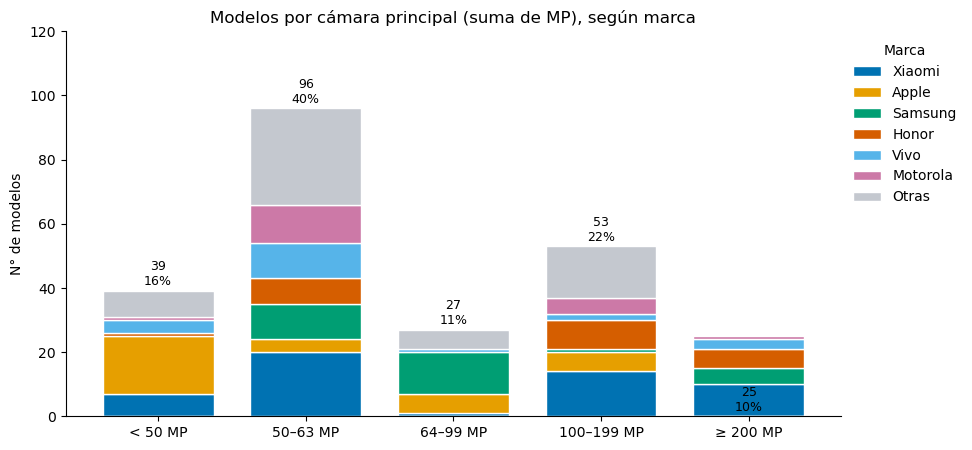

Marca,Xiaomi,Apple,Samsung,Honor,Vivo,Motorola,Otras
camara_principal_mp,,,,,,,
< 50 MP,7,18,0,1,4,1,8
50–63 MP,20,4,11,8,11,12,30
64–99 MP,1,6,13,0,1,0,6
100–199 MP,14,6,1,9,2,5,16
≥ 200 MP,10,0,5,6,3,1,0


In [27]:
barras_marca(tramo("camara_principal_mp", [0, 50, 64, 100, 200, 999], ["< 50 MP", "50–63 MP", "64–99 MP", "100–199 MP", "≥ 200 MP"]), "Modelos por cámara principal (suma de MP), según marca")